# Deep Learning Practical 3 — CNN for Dog/Cat Classification

This notebook recreates the code shown in the PDF. Update the CSV paths to match your environment. The CSV files must contain flattened RGB images (100 × 100 × 3) and corresponding labels.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten


## 1. Load and preprocess the data

The PDF uses local CSV files named `input.csv`, `labels.csv`, `input_test.csv`, and `labels_test.csv`. Place them in the working directory or change these paths.

In [2]:
# Change these paths if your CSV files are stored elsewhere.
X_train = np.loadtxt('input.csv', delimiter=',')
Y_train = np.loadtxt('labels.csv', delimiter=',')
X_test = np.loadtxt('input_test.csv', delimiter=',')
Y_test = np.loadtxt('labels_test.csv', delimiter=',')

X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)
X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train / 255.0
X_test = X_test / 255.0

print('Shape of X_train:', X_train.shape)
print('Shape of Y_train:', Y_train.shape)
print('Shape of X_test:', X_test.shape)
print('Shape of Y_test:', Y_test.shape)


Shape of X_train: (2000, 100, 100, 3)
Shape of Y_train: (2000, 1)
Shape of X_test: (400, 100, 100, 3)
Shape of Y_test: (400, 1)


## 2. Display a random training image

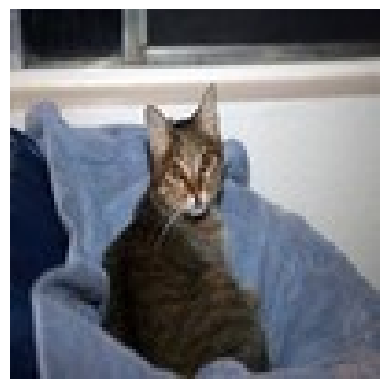

In [3]:
idx = random.randrange(len(X_train))
plt.imshow(X_train[idx])
plt.axis('off')
plt.show()


## 3. Build and train the CNN

The PDF shows both the list-based and `model.add()` styles for the same architecture. This notebook uses one equivalent model definition.

In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


C:\Users\Vaibhav\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 98, 98, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 47, 47, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 16928)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       1,083,456 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,093,665 (4.17 MB)

 Trainable params: 1,093,665 (4.17 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X_train, Y_train, epochs=10, batch_size=64)


Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.4920 - loss: 0.7618
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.5210 - loss: 0.6908
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.5820 - loss: 0.6787
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.6375 - loss: 0.6461
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.6695 - loss: 0.6108
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.6820 - loss: 0.5897
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.7200 - loss: 0.5529
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.7435 - loss: 0.5219
Epoch 9/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.7640 - loss: 0.4938
Epoch 10/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.7865 - loss: 0.4648


## 4. Evaluate on the test set

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.7000 - loss: 0.5913
Test loss: 0.5913192629814148
Test accuracy: 0.699999988079071


## 5. Predict a random test image

The original PDF maps a thresholded output of 0 to `dog` and 1 to `cat`. This assumes the dataset uses that label encoding.

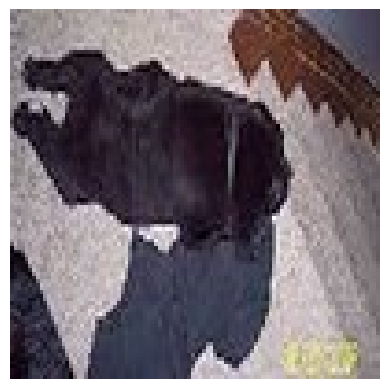

Our model says it is a: dog


In [7]:
idx2 = random.randrange(len(X_test))
plt.imshow(X_test[idx2])
plt.axis('off')
plt.show()

y_pred = model.predict(X_test[idx2:idx2 + 1], verbose=0)
pred = 'cat' if y_pred[0, 0] > 0.5 else 'dog'
print('Our model says it is a:', pred)
